In [3]:
# HEART DISEASE RISK CLASSIFIER USING SVM KERNELS
# Importing the required libraries


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

In [4]:
# Load the Heart Disease dataset
df = pd.read_csv('/content/heart.csv')

In [5]:
# Dataset dimensions
df.shape

(918, 12)

In [6]:
# Column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [7]:
# Check missing values in each column
df.isnull().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [8]:
# Check the distribution of target classes
df['HeartDisease'].value_counts()

,count
HeartDisease,
1,508
0,410


In [9]:
# Separate input features and target variable
X = df.drop(columns=['HeartDisease'])
y = df['HeartDisease']

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(
    include=['number']
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=['number']
).columns.tolist()

In [10]:
# Split the dataset into training and testing sets
# Stratification preserves the target-class proportions

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [11]:
# Numerical features: standardization
# Categorical features: one-hot encoding
# handle_unknown='ignore' handles unseen categories safely

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

In [12]:
# Define the SVM kernels to compare
kernels = ['linear', 'poly', 'rbf']

# Store trained pipelines and evaluation results
models = {}
results = []

for kernel in kernels:

    # Create a fresh preprocessing pipeline for each model
    model_pipeline = Pipeline([
        ('preprocessing', ColumnTransformer(
            transformers=[
                ('num', StandardScaler(), numeric_cols),
                ('cat', OneHotEncoder(handle_unknown='ignore'),
                 categorical_cols)
            ]
        )),
        ('svm', SVC(
            kernel=kernel,
            probability=True,
            random_state=42
        ))
    ])

    # Train the complete pipeline
    model_pipeline.fit(X_train, y_train)

    # Generate predictions on unseen test data
    y_pred = model_pipeline.predict(X_test)
    y_prob = model_pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)

    # Save the trained pipeline
    models[kernel] = model_pipeline

    # Store the results for comparison
    results.append({
        'Kernel': kernel,
        'Accuracy': accuracy,
        'AUC': auc_score
    })

results_df = pd.DataFrame(results)
results_df

,Kernel,Accuracy,AUC
0,linear,0.880435,0.931253
1,poly,0.875000,0.943926
2,rbf,0.896739,0.949426


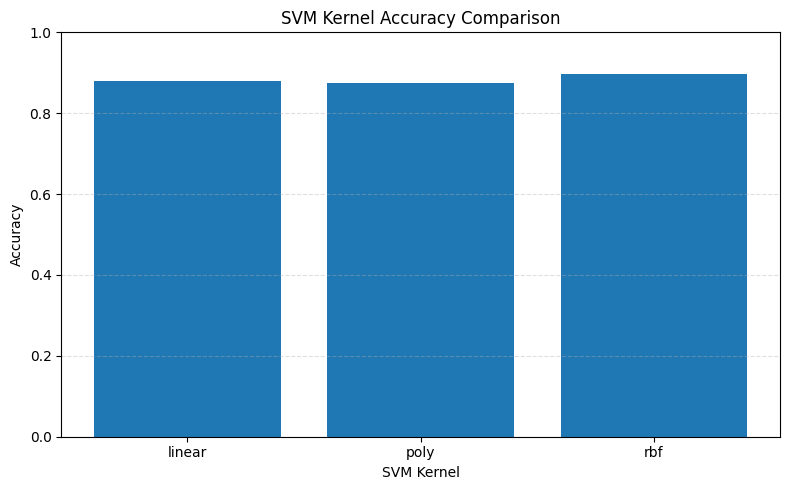

In [13]:
# Compare the accuracy of all SVM kernels

plt.figure(figsize=(8, 5))

plt.bar(
    results_df['Kernel'],
    results_df['Accuracy']
)

plt.xlabel('SVM Kernel')
plt.ylabel('Accuracy')
plt.title('SVM Kernel Accuracy Comparison')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [14]:
# Evaluate precision, recall, F1-score and support
# for each trained SVM kernel

for kernel, model in models.items():

    y_pred = model.predict(X_test)

    print(f"\nClassification Report: {kernel.upper()} Kernel\n")

    print(classification_report(
        y_test,
        y_pred,
        target_names=['No Heart Disease', 'Heart Disease'],
        zero_division=0
    ))


Classification Report: LINEAR Kernel

                  precision    recall  f1-score   support

No Heart Disease       0.91      0.82      0.86        82
   Heart Disease       0.86      0.93      0.90       102

        accuracy                           0.88       184
       macro avg       0.88      0.87      0.88       184
    weighted avg       0.88      0.88      0.88       184


Classification Report: POLY Kernel

                  precision    recall  f1-score   support

No Heart Disease       0.86      0.85      0.86        82
   Heart Disease       0.88      0.89      0.89       102

        accuracy                           0.88       184
       macro avg       0.87      0.87      0.87       184
    weighted avg       0.87      0.88      0.87       184


Classification Report: RBF Kernel

                  precision    recall  f1-score   support

No Heart Disease       0.91      0.85      0.88        82
   Heart Disease       0.89      0.93      0.91       102

        ac

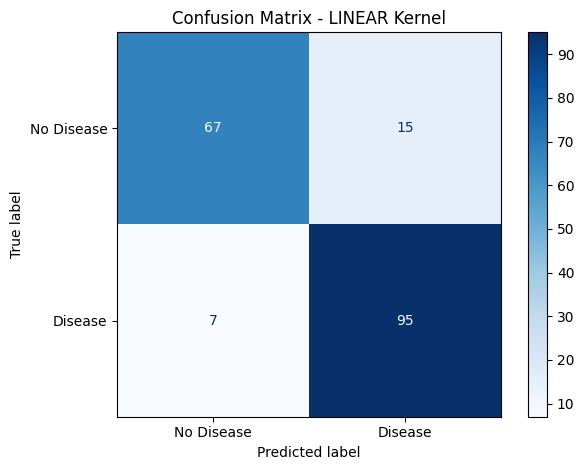

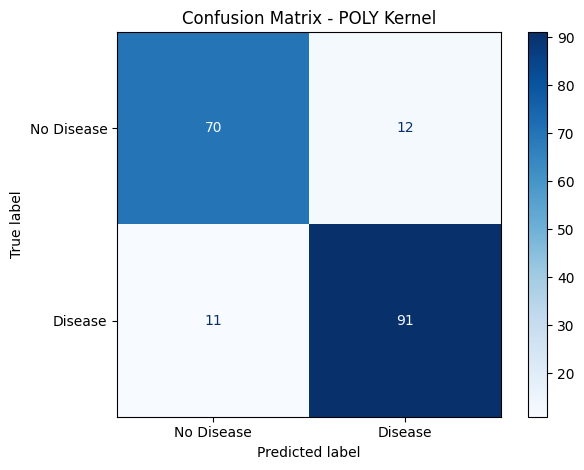

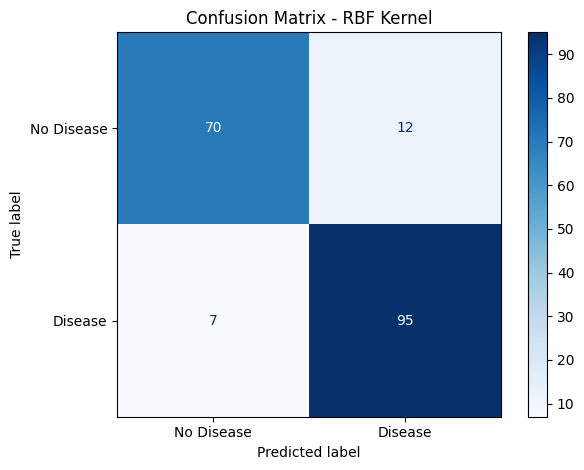

In [15]:
# Visualize correct and incorrect predictions
# separately for each SVM kernel

for kernel, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Disease', 'Disease']
    )

    disp.plot(cmap='Blues', values_format='d')

    plt.title(f'Confusion Matrix - {kernel.upper()} Kernel')
    plt.tight_layout()
    plt.show()

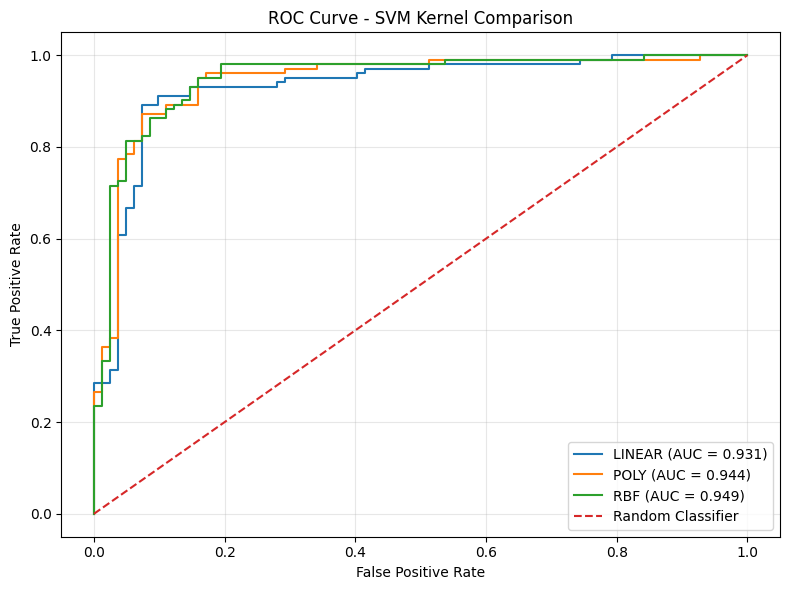

In [16]:
# Compare the ROC curves of all three SVM kernels

plt.figure(figsize=(8, 6))

for kernel, model in models.items():

    # Get predicted probability for the positive class
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate false positive and true positive rates
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    # Calculate Area Under the ROC Curve
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f'{kernel.upper()} (AUC = {auc_score:.3f})'
    )

# Reference line for random classification
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - SVM Kernel Comparison')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# Select the kernel with the highest test AUC
best_kernel = results_df.loc[
    results_df['AUC'].idxmax(),
    'Kernel'
]

best_model = models[best_kernel]

# Display the selected kernel and its evaluation metrics
results_df.sort_values(by='AUC', ascending=False)

,Kernel,Accuracy,AUC
2,rbf,0.896739,0.949426
1,poly,0.875000,0.943926
0,linear,0.880435,0.931253


In [18]:
# Save all three complete pipelines
# Each file includes preprocessing and the trained SVM model

joblib.dump(models, 'svm_all_kernels.joblib')

# Save the selected best-performing pipeline
joblib.dump(best_model, 'heart_disease_svm.joblib')

['heart_disease_svm.joblib']

In [19]:
# Download the trained models from Google Colab

from google.colab import files

files.download('svm_all_kernels.joblib')
files.download('heart_disease_svm.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>